In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("C:\\Users\\sanja\\python\\movies.csv")

In [3]:
df.shape

(7668, 15)

In [4]:
df.columns

Index(['name', 'rating', 'genre', 'year', 'released', 'score', 'votes',
       'director', 'writer', 'star', 'country', 'budget', 'gross', 'company',
       'runtime'],
      dtype='object')

In [5]:
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [8]:
df.isna().sum()

name           0
rating        77
genre          0
year           0
released       2
score          3
votes          3
director       0
writer         3
star           1
country        3
budget      2171
gross        189
company       17
runtime        4
dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7668 entries, 0 to 7667
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      7668 non-null   object 
 1   rating    7591 non-null   object 
 2   genre     7668 non-null   object 
 3   year      7668 non-null   int64  
 4   released  7666 non-null   object 
 5   score     7665 non-null   float64
 6   votes     7665 non-null   float64
 7   director  7668 non-null   object 
 8   writer    7665 non-null   object 
 9   star      7667 non-null   object 
 10  country   7665 non-null   object 
 11  budget    5497 non-null   float64
 12  gross     7479 non-null   float64
 13  company   7651 non-null   object 
 14  runtime   7664 non-null   float64
dtypes: float64(5), int64(1), object(9)
memory usage: 898.7+ KB


In [10]:
df.describe()

,year,score,votes,budget,gross,runtime
count,7668.000000,7665.000000,7.665000e+03,5.497000e+03,7.479000e+03,7664.000000
mean,2000.405451,6.390411,8.810850e+04,3.558988e+07,7.850054e+07,107.261613
std,11.153508,0.968842,1.633238e+05,4.145730e+07,1.657251e+08,18.581247
min,1980.000000,1.900000,7.000000e+00,3.000000e+03,3.090000e+02,55.000000
25%,1991.000000,5.800000,9.100000e+03,1.000000e+07,4.532056e+06,95.000000
50%,2000.000000,6.500000,3.300000e+04,2.050000e+07,2.020576e+07,104.000000
75%,2010.000000,7.100000,9.300000e+04,4.500000e+07,7.601669e+07,116.000000
max,2020.000000,9.300000,2.400000e+06,3.560000e+08,2.847246e+09,366.000000


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
duplicated_rows = df[df.duplicated()]
duplicated_rows.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime


In [16]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [17]:
df.isnull().sum()

name           0
rating        77
genre          0
year           0
released       2
score          3
votes          3
director       0
writer         3
star           1
country        3
budget      2171
gross        189
company       17
runtime        4
dtype: int64

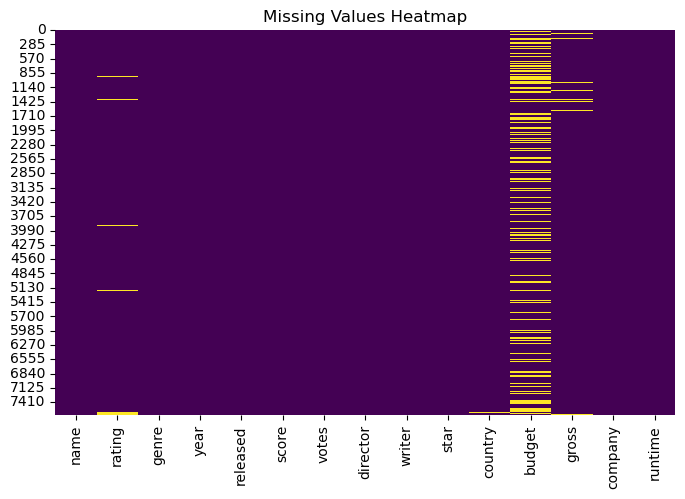

In [19]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [20]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=[object]).columns.tolist()
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['year', 'score', 'votes', 'budget', 'gross', 'runtime']
Categorical Columns: ['name', 'rating', 'genre', 'released', 'director', 'writer', 'star', 'country', 'company']


In [37]:
for col in numerical_cols:
    df[col].fillna(df[col].median(), inplace=True)
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [23]:
df.isnull().sum()

name        0
rating      0
genre       0
year        0
released    0
score       0
votes       0
director    0
writer      0
star        0
country     0
budget      0
gross       0
company     0
runtime     0
dtype: int64

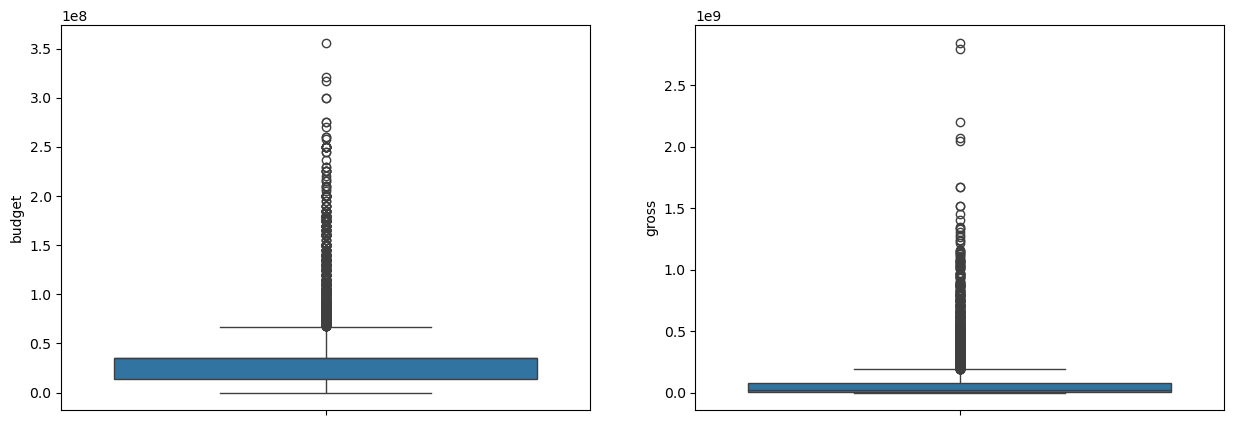

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(df['budget'], ax=ax[0])
sns.boxplot(df['gross'], ax=ax[1])
plt.show()
plt.show()

In [32]:
if df is None:
    df = pd.read_csv("C:\\Users\\sanja\\python\\movies.csv")
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
df=cap_outliers(df, 'budget')
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
    return df

if df is None:
    df = pd.read_csv("C:\\Users\\sanja\\python\\movies.csv")

df = cap_outliers(df, 'budget')
df = cap_outliers(df, 'gross')

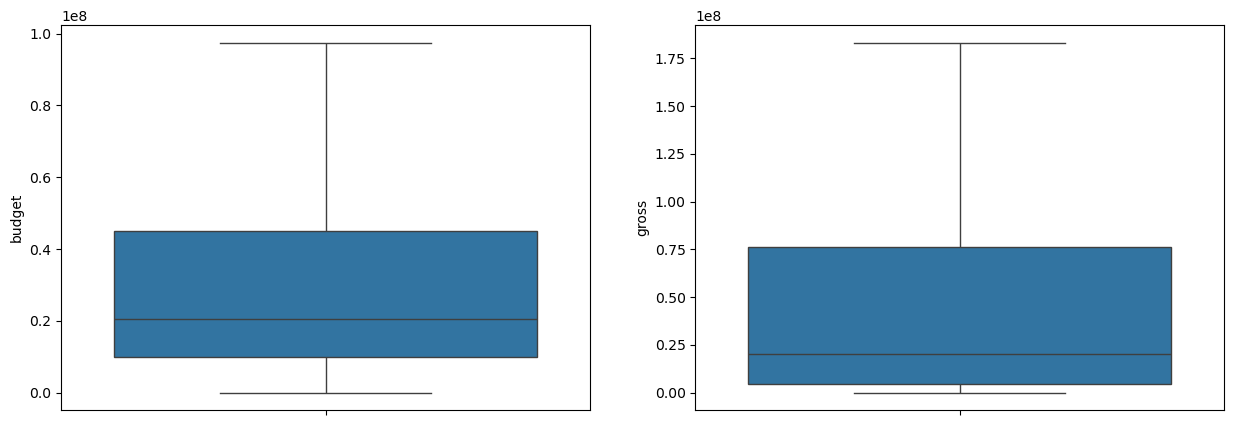

In [34]:
fig,ax=plt.subplots(1,2,figsize=(15,5))
sns.boxplot(df['budget'],ax=ax[0])
sns.boxplot(df['gross'],ax=ax[1])
plt.show()

Text(0.5, 1.0, 'Distribution of Budget')

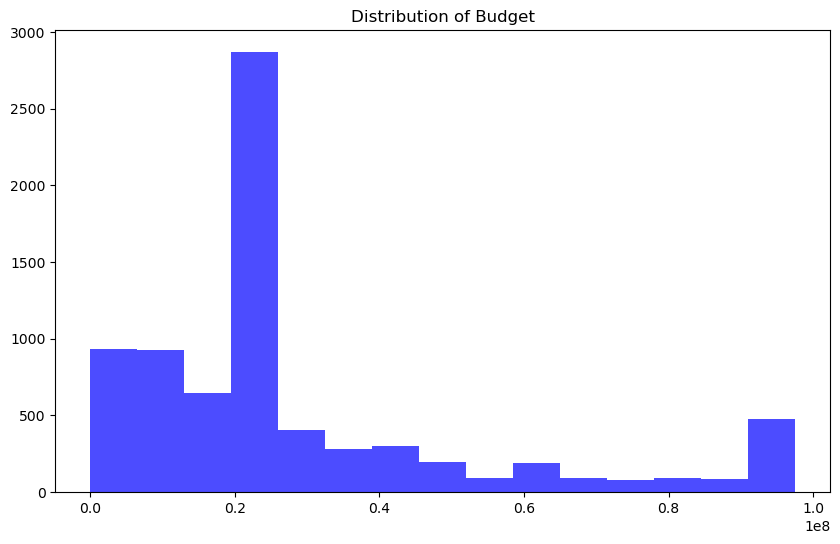

In [39]:
plt.figure(figsize=(10,6))
plt.hist(df['budget'], bins=15, color='blue', alpha=0.7)
plt.title('Distribution of Budget') 

<module 'matplotlib.pyplot' from 'c:\\Users\\sanja\\anaconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

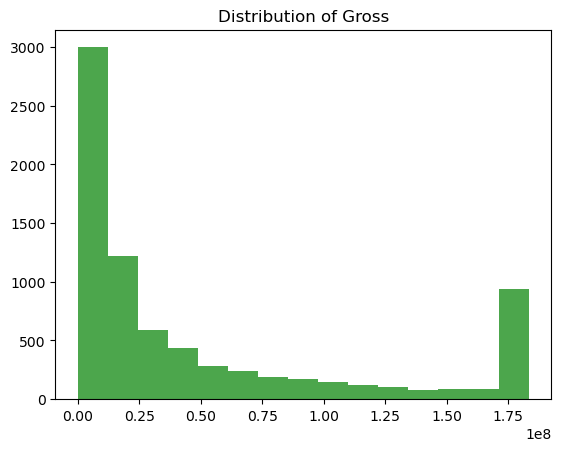

In [40]:
plt.hist(df['gross'], bins=15, color='green', alpha=0.7)
plt.title('Distribution of Gross')
plt

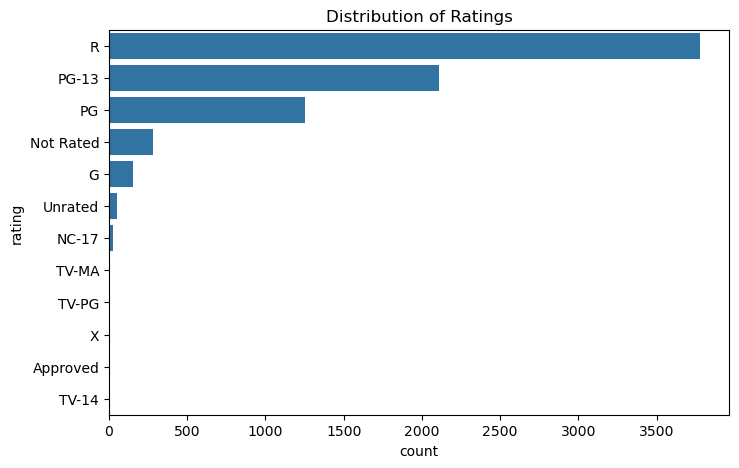

In [41]:
plt.figure(figsize=(8, 5))
sns.countplot(y=df["rating"], order=df["rating"].value_counts().index)
plt.title('Distribution of Ratings')
plt.show()

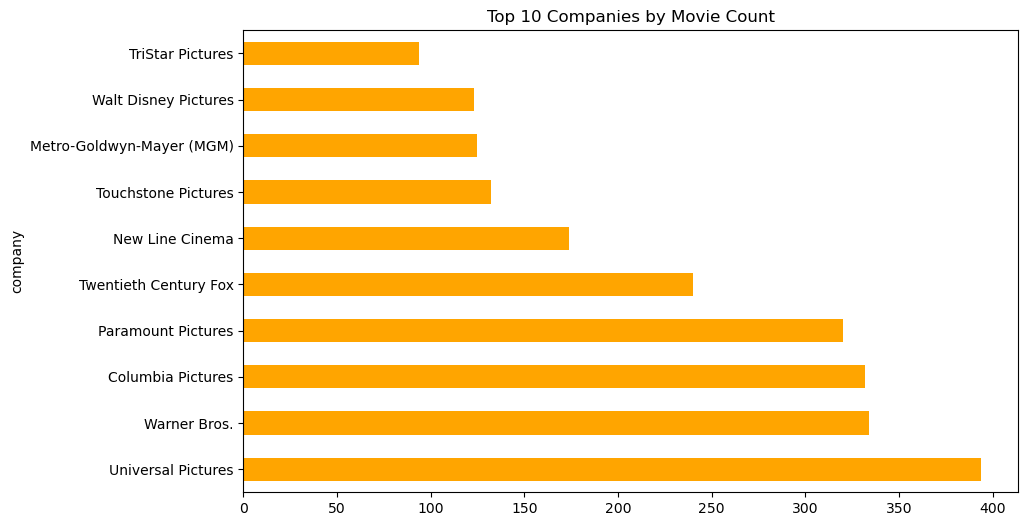

In [42]:
plt.figure(figsize=(10,6))
df["company"].value_counts().head(10).plot(kind='barh', color='orange')
plt.title('Top 10 Companies by Movie Count')
plt.show()

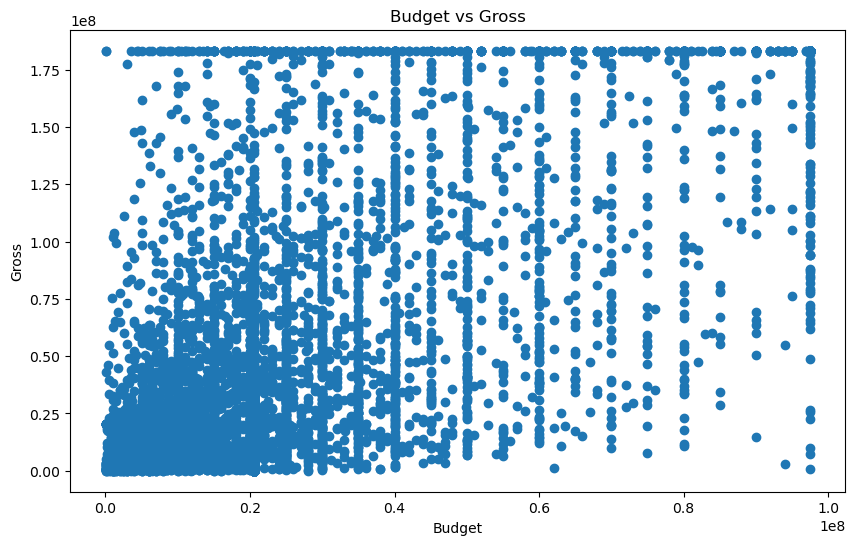

In [43]:
plt.figure(figsize=(10,6))
plt.scatter(df['budget'], df['gross'])
plt.title('Budget vs Gross')
plt.xlabel('Budget')
plt.ylabel('Gross')
plt.show()

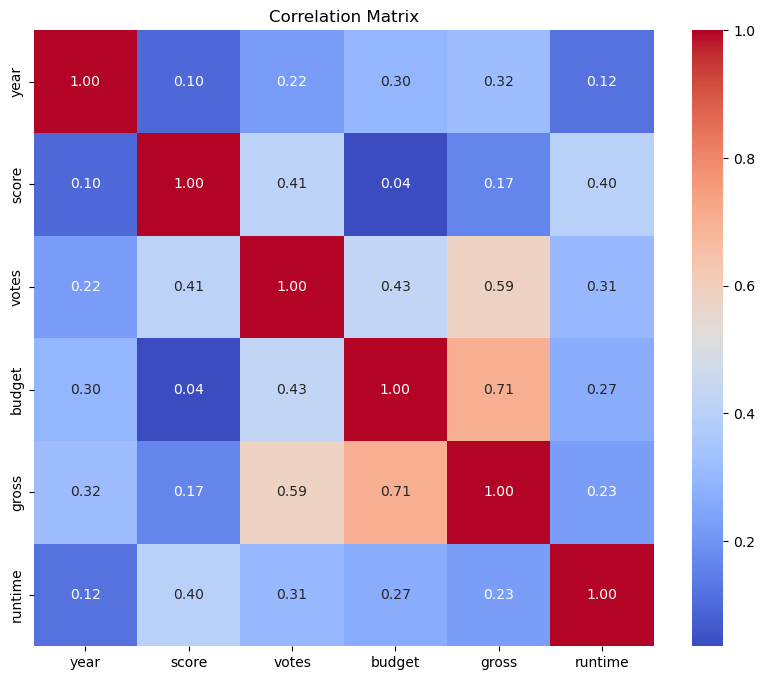

In [44]:
corr=df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

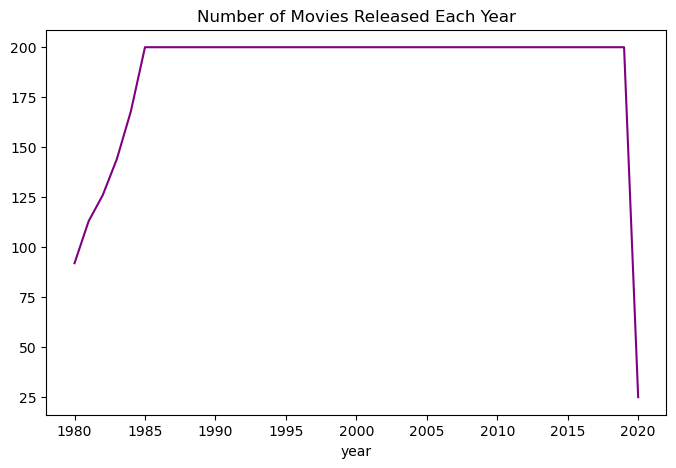

In [46]:
plt.figure(figsize=(8, 5))
df.groupby("year").size().plot(kind='line', color='purple')
plt.title('Number of Movies Released Each Year')
plt.show()

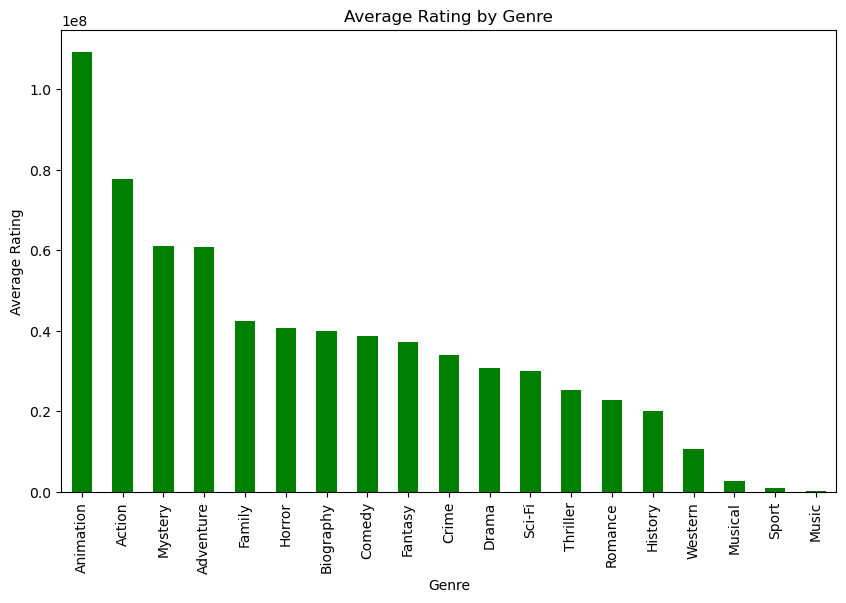

In [51]:
plt.figure(figsize=(10,6))
df.groupby('genre')[ 'gross' ].mean().sort_values(ascending=False).plot(kind='bar', color='green')
plt.title('Average Rating by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.show()

In [61]:
plt.figure(figsize=(10,6))
top_10_movies=df.sort_values(by="gross", ascending=False).head(10)
top_10_movies[["name","budget","gross"]]

,name,budget,gross
6079,John Carter,97500000.0,183243645.5
4083,xXx,70000000.0,183243645.5
6869,Rogue One: A Star Wars Story,97500000.0,183243645.5
4087,Die Another Day,97500000.0,183243645.5
1857,JFK,40000000.0,183243645.5
5941,The Green Hornet,97500000.0,183243645.5
5940,Battle Los Angeles,70000000.0,183243645.5
6863,Zootopia,97500000.0,183243645.5
6862,Passengers,97500000.0,183243645.5
6861,The Conjuring 2,40000000.0,183243645.5


<Figure size 1000x600 with 0 Axes>

In [62]:
df.to_csv("C:\\Users\\sanja\\python\\cleaned_movies.csv", index=False)
print("Cleaned data saved to cleaned_movies.csv")
df.head(5)

Cleaned data saved to cleaned_movies.csv


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,183243645.5,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0
